# 02 · Deep-Dive invsqrt: der echte 62-Qubit-Spitzen-Schaltkreis

Wir nehmen den invsqrt-Schaltkreis auseinander, **den wir gerade einreichen** (qvc-006/qvc-007, SHA `e4ed188b…`, aus der Assembler-Zusammenstellung von manwithacat, Autor Kirill Tymchishin). Wir legen ihn neben den **offiziellen Referenzschaltkreis** (260 Qubits).

| Abschnitt | Frage |
|---|---|
| 1 | Was liegt da? (Dateien, SHA, Steckbrief) |
| 2 | Was kostet er *offiziell*? (Verifier, Kostenformel, Rotationspreis) |
| 3 | Wie sieht die Referenz-Pipeline aus? (INFO_TAGs, Toffolis pro Stufe) |
| 4 | Wo steckt die Pipeline im SOTA-Schaltkreis? (ohne Tags: Phasen-Fortschritt, Z_POW-Blöcke) |
| 5 | Wie kommt er mit 62 Qubits aus? (Pebbling, bit-serielle Phase) |
| 6 | Stimmt er wirklich? (eigene Verifikation an einer Stichprobe) |
| 7 | Woher kommen die ~21×? |
| 8 | Wo liegen *unsere* Hebel – und welche sind schon gemessen tot? |

**Erinnerung an die Aufgabe:** `|x⟩|0…0⟩ → e^{2πi/√x}|x⟩|0…0⟩` für alle `x ∈ [1, 3.133.452]` (22-Bit-Register `x`). Die Toleranz liegt bei `tol(x) = 2⁻²⁴/√x` Umdrehungen, und zwar in **jedem** Shot.

**Konvention:** `read_shot_phase` liefert **Halbdrehungen**, das Ziel ist in **Umdrehungen** angegeben. Umrechnung: Umdrehungen = Halbdrehungen / 2.

In [1]:
import sys, time, hashlib, collections, math, re
from pathlib import Path
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import kickmix as km

ROOT = Path.cwd().resolve()
while not (ROOT / 'data' / 'verifiers').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'data' / 'verifiers'))
from invsqrt import verify_submission_invsqrt as V   # der OFFIZIELLE Verifier

SOTA_PATH = ROOT / 'work/frontier_scan/mwa_unpacked/invsqrt.kmb'   # = invsqrt in qvc-006/qvc-007
REF_PATH  = ROOT / 'data/sample_submission/invsqrt.kmb'            # = Referenzschaltkreis aus dem Paper
ASSETS = ROOT / 'docs' / 'learn' / 'assets'; ASSETS.mkdir(parents=True, exist_ok=True)

def sha(p): return hashlib.sha256(p.read_bytes()).hexdigest()
for name, p in [('SOTA', SOTA_PATH), ('Referenz', REF_PATH)]:
    print(f'{name:9s} {str(p.relative_to(ROOT)):45s} sha256={sha(p)[:12]}  {p.stat().st_size:,} Bytes')
assert sha(SOTA_PATH).startswith('e4ed188b'), 'unerwarteter SOTA-Schaltkreis'

sota = km.Circuit.from_file(str(SOTA_PATH))
ref  = km.Circuit.from_file(str(REF_PATH))
SPEC = V.ProblemSpecInvSqrt.for_n_p(10)
print('max_x =', SPEC.max_x, ' Registerbreite =', SPEC.width)

SOTA      work/frontier_scan/mwa_unpacked/invsqrt.kmb   sha256=e4ed188b6163  472,884 Bytes
Referenz  data/sample_submission/invsqrt.kmb            sha256=e2bf8eb64350  579,721 Bytes
max_x = 3133452  Registerbreite = 22


## 1 · Steckbrief: statische Zählung

„Statisch“ heißt: Wir zählen jede Instruktion in der Datei **einmal**. Der Verifier zählt später **pro Shot ausgeführte** Gatter. Das ist ein Unterschied, sobald Blöcke unter `PUSH_CONDITION` stehen, also nur laufen, wenn ein Messbit 1 ist.

In [2]:
def steckbrief(c):
    s = c.operation_statistics(); d = dict(s)
    return {
        'Qubits Q': c.num_qubits,
        'Instruktionen': len(c),
        'Toffoli-artig (CCX+CCZ+CSWAP)': s.num_toffoli_like,
        '  CCX': d.get('CCX', 0), '  CCZ': d.get('CCZ', 0), '  CSWAP': d.get('CSWAP', 0),
        'HMR (Messen+Reset, X-Basis)': d.get('HMR', 0),
        'R (Reset)': d.get('R', 0),
        'CX / CZ (gratis)': f"{d.get('CX', 0)} / {d.get('CZ', 0)}",
        'Z_POW gesamt': d.get('Z_POW', 0),
        '  davon T-artig': s.num_t_like,
        '  davon feine Rotationen (Stufe ≥ 4)': s.num_z_pow(min_clifford_hierarchy_level=4),
        'PUSH_CONDITION (bedingte Blöcke)': d.get('PUSH_CONDITION', 0),
        'INFO_TAG (Marker)': d.get('INFO_TAG', 0),
        'Reaktionstiefe': c.reaction_depth(),
    }
a, b = steckbrief(ref), steckbrief(sota)
print(f"{'':40s}{'Referenz':>12s}{'SOTA':>12s}")
for k in a:
    print(f'{k:40s}{str(a[k]):>12s}{str(b[k]):>12s}')

                                            Referenz        SOTA
Qubits Q                                         260          62
Instruktionen                                  62160       47535
Toffoli-artig (CCX+CCZ+CSWAP)                   7735        1487
  CCX                                           6915        1147
  CCZ                                              0         139
  CSWAP                                          820         201
HMR (Messen+Reset, X-Basis)                     6727         856
R (Reset)                                       6727          93
CX / CZ (gratis)                        28750 / 672329703 / 10833
Z_POW gesamt                                      40         113
  davon T-artig                                    1          40
  davon feine Rotationen (Stufe ≥ 4)              37          41
PUSH_CONDITION (bedingte Blöcke)                  56         332
INFO_TAG (Marker)                                628           0
Reaktionstiefe          

**Was sofort auffällt:**
- **Q: 260 → 62.** Das `x`-Register allein hat 22 Qubits. Der SOTA kommt also mit **40 Scratch-Qubits** aus, die Referenz braucht 238.
- **HMR: 6.727 → 856.** Die Referenz misst fast jedes AND-Hilfsbit einzeln weg (einfaches Muster). Der SOTA hat viel weniger Hilfsbits.
- **SOTA hat 332 bedingte Blöcke.** Teile des Schaltkreises laufen nur in manchen Shots. Deshalb ist die *mittlere* Toffoli-Zahl kleiner als die statische (siehe Abschnitt 2).
- **Der SOTA hat keine INFO_TAGs.** Seine Struktur müssen wir in Abschnitt 4 selbst finden.

## 2 · Offizielle Kosten mit dem echten Verifier

Wir rufen `verify()` aus `data/verifiers/invsqrt/verify_submission_invsqrt.py` auf, über **alle 3.133.452 x**, aber mit `shots_per_x=1` statt 64. Das dauert ~5 s statt ~5 min. Die Kostenzahlen sind dadurch eine Stichprobe der HMR-Zufallsausgänge, aber jedes `x` wird einmal komplett geprüft.

`batch_size=876`, weil der Verifier verlangt, dass die Shot-Zahl durch die Batchgröße teilbar ist (3.133.452 = 876 × 3.577).

In [3]:
spec1 = V.ProblemSpecInvSqrt.for_n_p(10, shots_per_x=1)
RES = {}
for name, c in [('Referenz', ref), ('SOTA', sota)]:
    t = time.time()
    RES[name] = V.verify(c, spec1, batch_size=876)
    print(f'{name}: {RES[name]["status"]} in {time.time()-t:.1f}s')
keys = ['num_qubits', 'toffoli_count', 'max_toffoli_count', 't_count', 'rotation_count',
        'rotation_eps', 'toffoli_equivalent', 'score', 'worst_error_over_tolerance', 'worst_x']
print(f"\n{'':28s}{'Referenz':>16s}{'SOTA':>16s}")
for k in keys:
    fa, fb = RES['Referenz'][k], RES['SOTA'][k]
    fmt = (lambda v: f'{v:.3e}') if k == 'rotation_eps' else (lambda v: f'{v:,.2f}' if isinstance(v, float) else f'{v:,}')
    print(f'{k:28s}{fmt(fa):>16s}{fmt(fb):>16s}')
ratio = RES['Referenz']['score'] / RES['SOTA']['score']
print(f'\nVerbesserungsfaktor Referenz/SOTA = {ratio:.4f}×')

Referenz: PASS in 4.8s


SOTA: PASS in 16.5s

                                    Referenz            SOTA
num_qubits                               260              62
toffoli_count                       7,735.00        1,289.29
max_toffoli_count                      7,735           1,487
t_count                                 1.00           20.50
rotation_count                         37.00           41.00
rotation_eps                       1.529e-12       2.434e-13
toffoli_equivalent                  7,987.59        1,589.26
score                           2,076,774.23       98,533.91
worst_error_over_tolerance              0.48            1.00
worst_x                            2,588,411             161

Verbesserungsfaktor Referenz/SOTA = 21.0767×


### Die Kostenformel Stück für Stück

```
C = (mittlere Toffolis pro Shot) + T/4
T = (T-Gatter pro Shot) + n_rot · (0.56·log2(1/ε) + 5.3)
Score = Q · C
```

**Woher kommt ε?** Feine Rotationen werden auf echter Hardware aus T-Gattern *approximiert* (Synthese). Je genauer, desto teurer, nämlich logarithmisch in 1/ε. Der Verifier berechnet ε so:
1. Er misst den **kleinsten Restspielraum** über alle Shots: `margin = min_x (tol(x) − |error(x)|)`.
2. Diesen Rest verteilt er gleichmäßig auf alle `n_rot` Rotationen: `ε = π · margin / n_rot` (mit margin in Umdrehungen).

Das heißt: **Wer die Toleranz selbst schon fast ausschöpft, hat wenig Rest, und jede Rotation wird teurer.** Rechnen wir das nach:

Referenz: Toffolis (Mittel/Shot)=7,735.0, T-Gatter / 4=0.2, Rotationen / 4=252.3  → C=7,987.6 (Verifier: 7,987.6)
   pro Rotation 27.28 T;  margin = 332,168,080 Einheiten à 2^-64 Umdrehungen
SOTA: Toffolis (Mittel/Shot)=1,289.3, T-Gatter / 4=5.1, Rotationen / 4=294.8  → C=1,589.3 (Verifier: 1,589.3)
   pro Rotation 28.76 T;  margin = 58,597,850 Einheiten à 2^-64 Umdrehungen


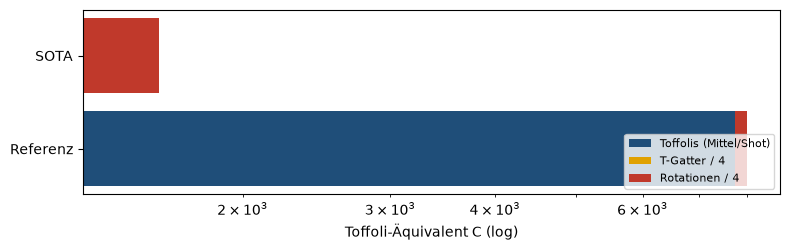

SOTA: Rotationen machen 18.6% von C aus.
Toffolis: statisch 1,487 vs. Mittel 1,289.3 → 13.3% gespart durch bedingte Blöcke


In [4]:
def zerlegung(r):
    rot_T = r['rotation_count'] * V.rotation_t_count(r['rotation_eps']) if r['rotation_count'] else 0.0
    parts = {'Toffolis (Mittel/Shot)': r['toffoli_count'],
             'T-Gatter / 4': r['t_count'] / 4,
             'Rotationen / 4': rot_T / 4}
    margin_units = r['rotation_eps'] * r['rotation_count'] * 2**64 / math.pi if r['rotation_count'] else None
    return parts, rot_T, margin_units

fig, ax = plt.subplots(figsize=(8, 2.6))
for i, name in enumerate(['Referenz', 'SOTA']):
    parts, rot_T, margin = zerlegung(RES[name])
    left = 0
    for (lab, v), col in zip(parts.items(), ['#1f4e79', '#e0a100', '#c0392b']):
        ax.barh(i, v, left=left, color=col, label=lab if i == 0 else None); left += v
    print(f'{name}: ' + ', '.join(f'{k}={v:,.1f}' for k, v in parts.items()) +
          f'  → C={sum(parts.values()):,.1f} (Verifier: {RES[name]["toffoli_equivalent"]:,.1f})')
    print(f'   pro Rotation {V.rotation_t_count(RES[name]["rotation_eps"]):.2f} T;  margin = {margin:,.0f} Einheiten à 2^-64 Umdrehungen')
ax.set_yticks([0, 1]); ax.set_yticklabels(['Referenz', 'SOTA']); ax.set_xscale('log')
ax.set_xlabel('Toffoli-Äquivalent C (log)'); ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

parts, rot_T, _ = zerlegung(RES['SOTA'])
print(f"SOTA: Rotationen machen {parts['Rotationen / 4']/RES['SOTA']['toffoli_equivalent']:.1%} von C aus.")
print(f"Toffolis: statisch {RES['SOTA']['max_toffoli_count']:,} vs. Mittel {RES['SOTA']['toffoli_count']:,.1f} "
      f"→ {1-RES['SOTA']['toffoli_count']/RES['SOTA']['max_toffoli_count']:.1%} gespart durch bedingte Blöcke")

**Merke:**
- Beim SOTA kosten die **41 feinen Rotationen fast ein Fünftel** von C. Der Rest sind fast nur Toffolis.
- `worst_error_over_tolerance` liegt beim SOTA bei ≈ **0,999**, bei der Referenz bei 0,48. Der SOTA nutzt das Fehlerbudget also **fast vollständig aus**, damit er an Toffolis sparen kann. Die Rotationen bekommen dadurch nur einen kleinen Rest, und genau der wurde optimiert (LP-Fit, siehe Abschnitt 8).
- **Sensitivität:** Doppelt so viel Rest (margin × 2) spart pro Rotation 0,56 T, insgesamt also `41·0.56/4 ≈ 5.7` Toffoli-Äquivalente. Das ist **wenig**, weil der Rest nur logarithmisch eingeht.

## 3 · Referenz-Pipeline: was jede Stufe kostet

Die Referenz ist mit `INFO_TAG "@enter:…"/"@exit:…"` annotiert. Daraus können wir jede Toffoli-artige Operation ihrer Stufe zuordnen. Die Stufen entsprechen genau der Pipeline aus der Erklärung:

`normalize → select_interval → load_coefficients → horner (Seed) → square → multiply_m → correct → multiply_y0 (Newton) → denormalize → phase_by_bits → alles rückwärts`

Stufe                 vorwärts  rückwärts
normalize                  120        110
select_interval              3          0
load_coefficients            0          0
horner                   1,071      1,071
square                     442        442
multiply_m               1,043      1,043
correct                     28         28
multiply_y0                867        867
denormalize                300        300
phase_by_bits                0
Summe: 7735 (statisch erwartet 7.735)


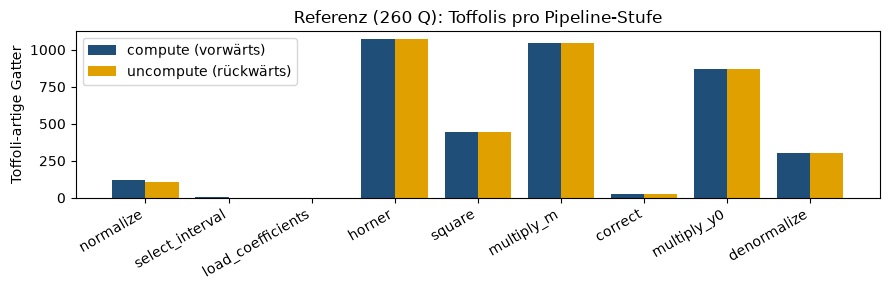

Flame-Chart gespeichert: docs/learn/assets/invsqrt_reference_flame.svg


In [5]:
TOFF = ('CCX', 'CCZ', 'CSWAP')
def lines_of(c):
    return [l for l in str(c).splitlines() if not l.startswith(('APPEND_TO_REGISTER', 'REGISTER'))]

def attribution(c):
    stack, cnt = [], collections.Counter()
    for l in lines_of(c):
        if l.startswith('INFO_TAG'):
            tag = l.split('"')[1]
            kind, name = tag[1:].split(':', 1)
            if kind == 'enter': stack.append(name)
            else: stack.pop()
        elif l.split()[0] in TOFF:
            key = (stack[0] if stack else '-', stack[1] if len(stack) > 1 else '-')
            cnt[key] += 1
    return cnt

att = attribution(ref)
order = ['normalize', 'select_interval', 'load_coefficients', 'horner', 'square',
         'multiply_m', 'correct', 'multiply_y0', 'denormalize']
fw = [att[('compute_y1', s)] for s in order]
bw = [att[('uncompute_y1', s)] for s in order]
print(f"{'Stufe':20s}{'vorwärts':>10s}{'rückwärts':>11s}")
for s, f_, b_ in zip(order, fw, bw): print(f'{s:20s}{f_:>10,}{b_:>11,}')
print(f"{'phase_by_bits':20s}{att[('phase_by_bits','-')]:>10,}")
print('Summe:', sum(att.values()), '(statisch erwartet 7.735)')

x_ = np.arange(len(order))
plt.figure(figsize=(9, 3))
plt.bar(x_ - 0.2, fw, 0.4, label='compute (vorwärts)', color='#1f4e79')
plt.bar(x_ + 0.2, bw, 0.4, label='uncompute (rückwärts)', color='#e0a100')
plt.xticks(x_, order, rotation=30, ha='right'); plt.ylabel('Toffoli-artige Gatter')
plt.title('Referenz (260 Q): Toffolis pro Pipeline-Stufe'); plt.legend(); plt.tight_layout(); plt.show()

(ASSETS / 'invsqrt_reference_flame.svg').write_text(ref.flame_chart_svg())
print('Flame-Chart gespeichert:', (ASSETS / 'invsqrt_reference_flame.svg').relative_to(ROOT))

**Lesart:**
- Die Referenz ist **streng symmetrisch**: Vorwärts und rückwärts kosten pro Stufe exakt gleich viel. Ausnahmen sind nur `normalize` (120/110) und `select_interval` (3/0). Jede Stufe wird also 1:1 rückwärts wieder abgebaut, und die Hälfte aller Toffolis ist reine Uncomputation.
- **Seed (`horner`) + Newton (`square`, `multiply_m`, `multiply_y0`) machen ~88 % aus.** Dort muss jede Optimierung ansetzen.
- `load_coefficients` und `phase_by_bits` kosten **0 Toffolis**: Das Laden der Konstanten und das Phasen der Bits besteht nur aus gratis Gattern bzw. Rotationen.
- Der Flame-Chart ([assets/invsqrt_reference_flame.svg](assets/invsqrt_reference_flame.svg)) zeigt, welche Stufe wie viele Qubits gleichzeitig belegt. Im Browser öffnen.

## 4 · Die Pipeline im SOTA-Schaltkreis finden (ohne Marker)

Der SOTA hat keine Tags. Wir orten die Stufen mit drei Messungen:
1. **Wo stehen die Z_POW-Gatter?** Dort wird die Phase aufgebracht.
2. **Welche Winkel?** Wir sortieren sie in Clifford (gratis), T und fein (teuer).
3. **Phasen-Fortschritt:** Wir simulieren nur die ersten *n* Instruktionen und messen, wie nah die Phase schon an `1/√x` liegt.

In [6]:
S_LINES = lines_of(sota)
zp = []
for i, l in enumerate(S_LINES):
    if l.startswith('Z_POW'):
        tok = l.split()
        ht = Fraction(tok[2])
        zp.append(dict(i=i, q=tok[1], ht=ht, cls=V.z_pow_class(ht), cond=' if ' in l))
# Blöcke = Z_POW-Läufe mit Lücken < 1000 Instruktionen
blocks, cur = [], [zp[0]]
for z in zp[1:]:
    if z['i'] - cur[-1]['i'] > 1000: blocks.append(cur); cur = [z]
    else: cur.append(z)
blocks.append(cur)
print(f'{len(S_LINES):,} Instruktionen, {len(zp)} Z_POW in {len(blocks)} Blöcken:\n')
for k, bl in enumerate(blocks):
    c = collections.Counter(z['cls'] for z in bl)
    qs = collections.Counter(z['q'] for z in bl).most_common(3)
    print(f'Block {k}: Instr. {bl[0]["i"]:>6,}–{bl[-1]["i"]:>6,}  {dict(c)}  bedingt={sum(z["cond"] for z in bl)}  Qubits={qs}')

47,535 Instruktionen, 113 Z_POW in 4 Blöcken:

Block 0: Instr. 15,280–15,618  {'clifford': 6, 'rotation': 15, 't': 1}  bedingt=0  Qubits=[('q28', 16), ('q0', 2), ('q2', 2)]
Block 1: Instr. 25,657–25,897  {'rotation': 26}  bedingt=0  Qubits=[('q50', 21), ('q28', 3), ('q41', 1)]
Block 2: Instr. 29,036–31,098  {'clifford': 22, 't': 33}  bedingt=55  Qubits=[('q30', 10), ('q46', 10), ('q57', 6)]
Block 3: Instr. 35,485–35,731  {'clifford': 4, 't': 6}  bedingt=10  Qubits=[('q39', 4), ('q38', 4), ('q60', 1)]


In [7]:
fine = [z for z in zp if z['cls'] == 'rotation']
print(f'{len(fine)} feine Rotationen. Winkel in Umdrehungen vs. nächste Zweierpotenz 2^-k:\n')
print(f"{'Instr.':>7s} {'Qubit':>5s} {'Umdrehungen':>14s} {'k':>3s} {'Abweichung':>11s}")
for z in fine:
    turns = float(z['ht']) / 2
    k = round(-math.log2(turns))
    print(f"{z['i']:>7,} {z['q']:>5s} {turns:>14.6e} {k:>3d} {turns*2**k-1:>+11.2e}")

41 feine Rotationen. Winkel in Umdrehungen vs. nächste Zweierpotenz 2^-k:

 Instr. Qubit    Umdrehungen   k  Abweichung
 15,289   q28   3.814698e-06  18   +1.78e-07
 15,297   q28   7.629394e-06  17   -8.74e-08
 15,305   q28   1.525879e-05  16   -1.06e-07
 15,313   q28   3.051758e-05  15   +2.59e-08
 15,320   q28   6.103515e-05  14   -6.18e-08
 15,329   q28   1.220703e-04  13   -2.47e-08
 15,338   q28   2.441406e-04  12   +2.95e-09
 15,347   q28   4.882813e-04  11   +2.58e-09
 15,396   q28   9.765625e-04  10   -1.24e-08
 15,450   q28   1.953125e-03   9   -7.76e-09
 15,504   q28   3.906250e-03   8   -5.23e-09
 15,552   q28   7.812500e-03   7   -9.35e-09
 15,599   q28   1.562500e-02   6   +1.08e-08
 15,604   q28   3.125000e-02   5   -2.77e-08
 15,609   q28   6.250000e-02   4   +1.46e-08
 25,657   q50   1.443038e-11  36   -8.35e-03
 25,667   q50   2.936391e-11  35   +8.94e-03
 25,675   q50   5.794138e-11  34   -4.57e-03
 25,683   q50   1.163348e-10  33   -6.92e-04
 25,694   q50   2.327250e

**Was die Tabelle zeigt (direkt aus der Datei):**
- Die feinen Winkel sind **fast**, aber **nicht exakt** Zweierpotenzen. In Block 0 weichen sie nur um ~10⁻⁸…10⁻⁷ ab, in Block 1 (die feinsten Bits) um bis zu ~10⁻². Diese Gewichte sind **nachoptimiert**: Sie gleichen den systematischen Fehler der Arithmetik aus, damit überall `|error| ≤ tol − c` gilt. Nach Subagent B ist das die Lösung eines Minimax-LP.
- Exakte Zweierpotenzen ab 2⁻³ Umdrehungen abwärts wären *trotzdem* feine Rotationen. Gratis sind nur Clifford-Winkel (½, ¼ Umdrehung), und ⅛ Umdrehung ist ein T-Gatter.
- Die bedingten Winkel 1,75/0,25 Halbdrehungen im letzten Block sind **T-Gatter unter `if b…`**. Sie sind Phasenkorrekturen der messbasierten Uncomputation und laufen nur, wenn das Messbit 1 war.

65 Teil-Simulationen in 0.3s


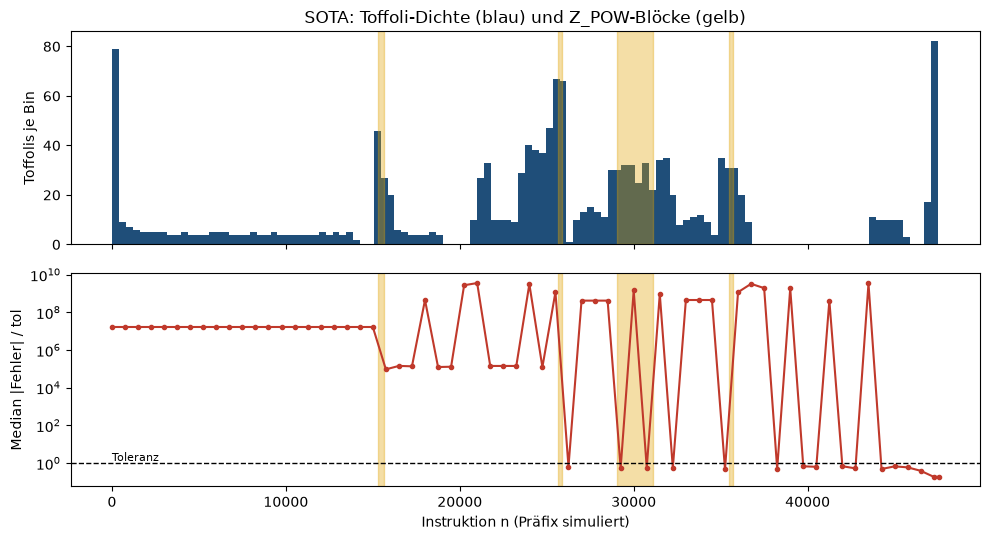

nach      0 Instr.: Median |Fehler| = 7.81e-04 Umdr. = 1.68e+07 × tol
nach 15,000 Instr.: Median |Fehler| = 7.81e-04 Umdr. = 1.68e+07 × tol
nach 15,750 Instr.: Median |Fehler| = 4.51e-06 Umdr. = 9.48e+04 × tol
nach 25,500 Instr.: Median |Fehler| = 5.00e-01 Umdr. = 1.19e+09 × tol
nach 26,250 Instr.: Median |Fehler| = 7.86e-11 Umdr. = 6.59e-01 × tol
nach 28,500 Instr.: Median |Fehler| = 2.50e-01 Umdr. = 4.21e+08 × tol
nach 29,250 Instr.: Median |Fehler| = 4.05e-11 Umdr. = 5.45e-01 × tol
nach 30,750 Instr.: Median |Fehler| = 3.76e-11 Umdr. = 5.84e-01 × tol
nach 31,500 Instr.: Median |Fehler| = 2.50e-01 Umdr. = 9.38e+08 × tol
nach 35,250 Instr.: Median |Fehler| = 2.91e-11 Umdr. = 4.71e-01 × tol
nach 36,000 Instr.: Median |Fehler| = 5.00e-01 Umdr. = 1.18e+09 × tol
nach 47,535 Instr.: Median |Fehler| = 9.56e-12 Umdr. = 1.88e-01 × tol


In [8]:
HEAD = [l for l in str(sota).splitlines() if l.startswith(('APPEND_TO_REGISTER', 'REGISTER'))]
XREG = sota.register_data['x']
def to_bits(v, w=22): return V.to_bits(np.asarray(v, dtype=np.uint64), w)

rng = np.random.default_rng(7)
xs_probe = np.sort(rng.integers(1, SPEC.max_x + 1, 512).astype(np.uint64))
tgt_probe, tol_probe = V.reference_values(SPEC, xs_probe)

def phase_err_after(n):
    circ = km.Circuit('\n'.join(HEAD + S_LINES[:n]))
    sim = km.Simulator(batch_size=len(xs_probe), debug_print=False, seed=1)
    sim.write_across_shots(XREG, to_bits(xs_probe)); sim.do(circ)
    th = np.array([V.half_turns_to_units(Fraction(sim.read_shot_phase(i))) for i in range(len(xs_probe))], dtype=np.uint64)
    err = np.abs((th - tgt_probe).view(np.int64)).astype(float) / 2**64     # Umdrehungen
    return np.median(err), np.median(err / (tol_probe.astype(float) / 2**64))

checkpoints = list(range(0, len(S_LINES), 750)) + [len(S_LINES)]
t = time.time()
prog = np.array([phase_err_after(n) for n in checkpoints])
print(f'{len(checkpoints)} Teil-Simulationen in {time.time()-t:.1f}s')

# Toffoli-Dichte
pos = np.array([i for i, l in enumerate(S_LINES) if l.split()[0] in TOFF])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
a1.hist(pos, bins=120, color='#1f4e79'); a1.set_ylabel('Toffolis je Bin')
for bl in blocks:
    for ax in (a1, a2): ax.axvspan(bl[0]['i'], bl[-1]['i'], color='#e0a100', alpha=0.35)
a1.set_title('SOTA: Toffoli-Dichte (blau) und Z_POW-Blöcke (gelb)')
a2.semilogy(checkpoints, prog[:, 1], 'o-', color='#c0392b', ms=3)
a2.axhline(1, ls='--', c='k', lw=1); a2.text(0, 1.3, 'Toleranz', fontsize=8)
a2.set_ylabel('Median |Fehler| / tol'); a2.set_xlabel('Instruktion n (Präfix simuliert)')
plt.tight_layout(); plt.show()
for n, (e, r) in zip(checkpoints, prog):
    if n in (0, len(S_LINES)) or any(abs(n - bl[0]['i']) < 750 or abs(n - bl[-1]['i']) < 750 for bl in blocks):
        print(f'nach {n:>6,} Instr.: Median |Fehler| = {e:.2e} Umdr. = {r:.2e} × tol')

**Interpretation.** Gemessen ist der Phasenfehler nach jedem Präfix. Die Zuordnung zu den Pipeline-Stufen ist unsere Deutung, passt aber zu allen Zahlen:

| Bereich | Was passiert | Indiz |
|---|---|---|
| Anfang bis Block 0 | **Normalisieren + Seed** berechnen, noch keine Phase | viele Toffolis, Fehler ≈ 1/√x selbst |
| **Block 0** | **grobe Phase**: die höherwertigen Bits (15 feine Winkel 2⁻¹⁸…2⁻⁴ Umdr., dazu Clifford/T) | Fehler fällt auf ~5·10⁻⁶ Umdr. |
| zwischen Block 0 und 1 | **Newton-Korrektur** berechnen | dichteste Toffoli-Region |
| **Block 1** | **feine Phase**: die niederwertigen Bits (26 feine Winkel 2⁻³⁶…2⁻¹¹ Umdr.) | Fehler fällt unter die Toleranz (Median ≈ 0,66·tol) |
| Block 2, 3 bis Ende | **Uncompute** + Phasenkorrekturen (nur bedingte Clifford/T, keine feinen Winkel) | Fehler springt zwischendurch auf ±¼ bzw. ½ Umdr. und landet am Ende bei Median ≈ 0,19·tol |

Zwischen den Blöcken springt der Fehler zeitweise auf ¼ oder ½ Umdrehung. Das ist kein Bug: Halb abgebaute Hilfsbits und HMR-Messungen hinterlassen vorübergehend Vorzeichen-Phasen, die die Uncomputation am Ende wieder exakt aufhebt.

**Die Kernidee gegenüber der Referenz:** Die Phase wird **in zwei Raten** aufgebracht, grob nach dem Seed und fein nach der Korrektur. Die Referenz phast dagegen erst das fertige `y₁`. Ob der SOTA intern genau `y₀` und dann `y₁ − y₀` phast, haben wir **nicht** im Detail nachgewiesen (offen).

## 5 · Wie passt das in 62 Qubits? Bit-serielle Phase und Pebbling

### 5a · Die Phase wird bit-seriell durch *ein* Qubit geschoben
Block 0 benutzt fast nur **q28** als Ziel. Schauen wir uns das Muster an:

In [9]:
b0 = blocks[0]
i0 = [z for z in b0 if z['cls'] == 'rotation'][0]['i']
for i in range(i0 - 6, i0 + 17):
    mark = '  ◀── Phase' if S_LINES[i].startswith('Z_POW') else ('  ◀── wegmessen' if S_LINES[i].startswith('HMR') else '')
    print(f'{i:>6}  {S_LINES[i]}{mark}')

 15283  CX q23 q21
 15284  CSWAP q21 q50 q1
 15285  CX q50 q28
 15286  CX q23 q21
 15287  CSWAP q20 q28 q2
 15288  CSWAP q27 q28 q0
 15289  Z_POW q28 0.000007629395892507352498757011716179476934485137462615966796875  ◀── Phase
 15290  HMR q28 b388  ◀── wegmessen
 15291  CX q23 q21
 15292  CX q51 q28
 15293  CCX q21 q51 q28
 15294  CX q23 q21
 15295  CSWAP q20 q28 q3
 15296  CSWAP q27 q28 q0
 15297  Z_POW q28 0.000015258787729483728849710910679959852132014930248260498046875  ◀── Phase
 15298  HMR q28 b389  ◀── wegmessen
 15299  CX q23 q21
 15300  CX q40 q28
 15301  CCX q21 q40 q28
 15302  CX q23 q21
 15303  CSWAP q20 q28 q2
 15304  CSWAP q27 q28 q0
 15305  Z_POW q28 0.000030517574903903325021781167691869995906017720699310302734375  ◀── Phase


Das Muster wiederholt sich: **Bit nach q28 rechnen** (CX/CCX/CSWAP) → **`Z_POW` mit dem Gewicht dieses Bits** → **`HMR q28`** (messbasiert löschen, 0 Toffolis) → nächstes Bit.

Die Referenz hält dagegen das ganze Ausgaberegister `y₁` (Dutzende Qubits) gleichzeitig, phast es und baut es wieder ab. **Streaming** spart diese Breite fast vollständig. Weil `Q` im Score *multipliziert*, ist das einer der größten Einzelhebel.

Referenz: 238 Scratch-Qubits | Neustarts je Qubit: Median 0, max 384 | Ops je Qubit: Median 244 | mittlere Lebensdauer 72% der Laufzeit
SOTA: 40 Scratch-Qubits | Neustarts je Qubit: Median 8, max 118 | Ops je Qubit: Median 1510 | mittlere Lebensdauer 95% der Laufzeit


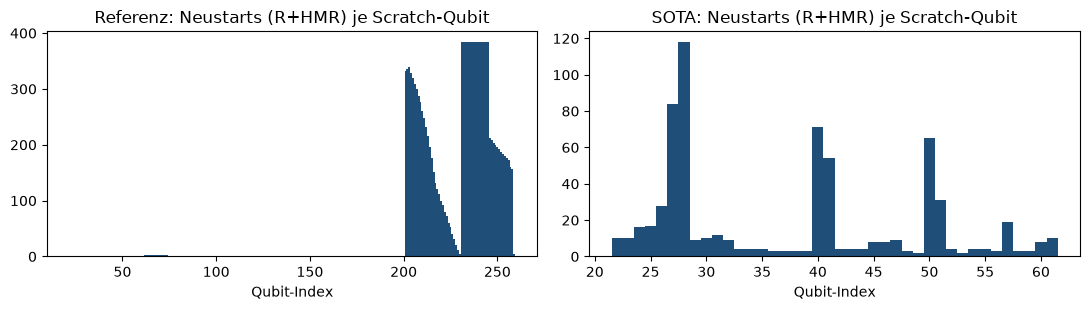

In [10]:
def per_qubit(c):
    L = lines_of(c); n = c.num_qubits
    ops = np.zeros(n, int); resets = np.zeros(n, int); first = np.full(n, -1); last = np.full(n, -1)
    for i, l in enumerate(L):
        tok = l.split()
        for t_ in tok[1:]:
            if t_ == 'if': break
            if t_.startswith('q') and t_[1:].isdigit():
                q = int(t_[1:]); ops[q] += 1
                if first[q] < 0: first[q] = i
                last[q] = i
        if tok[0] in ('R', 'HMR'): resets[int(tok[1][1:])] += 1
    return ops, resets, first, last, len(L)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (name, c) in zip(axes, [('Referenz', ref), ('SOTA', sota)]):
    ops, resets, first, last, N = per_qubit(c)
    scratch = np.arange(22, c.num_qubits)
    ax.bar(scratch, resets[scratch], color='#1f4e79', width=1.0)
    ax.set_title(f'{name}: Neustarts (R+HMR) je Scratch-Qubit'); ax.set_xlabel('Qubit-Index')
    life = (last[scratch] - first[scratch]) / N
    print(f'{name}: {len(scratch)} Scratch-Qubits | Neustarts je Qubit: Median {np.median(resets[scratch]):.0f}, '
          f'max {resets[scratch].max()} | Ops je Qubit: Median {np.median(ops[scratch]):.0f} | '
          f'mittlere Lebensdauer {life.mean():.0%} der Laufzeit')
plt.tight_layout(); plt.show()

**Pebbling = Qubits recyceln.** Ein „Neustart“ (R oder HMR) beendet eine Nutzung des Qubits, danach kann es für etwas anderes verwendet werden.
- **Referenz:** Der Median liegt bei **0 Neustarts**. Die meisten der 238 Scratch-Qubits sind feste Register (Koeffizienten, Quadrat, Produkt, `y₁`), die einmal belegt werden und bis zum Abbau warten. Nur wenige AND-Hilfsqubits werden extrem oft recycelt (bis 384×).
- **SOTA:** Der Median liegt bei **8 Neustarts** und ~1.500 Operationen je Qubit. Fast jedes der 40 Scratch-Qubits ist über ~95 % der Laufzeit im Einsatz. Leerlauf gibt es praktisch nicht.

Die Kehrseite: Wer Qubits früh wiederverwendet, kann Zwischenergebnisse **nicht** einfach rückwärts abbauen. Man muss sie neu berechnen oder messbasiert löschen. Genau dieser Zielkonflikt zwischen Raum und Zeit ist das Handwerk.

## 6 · Selbst verifizieren an einer Stichprobe

Jetzt prüfen wir ohne die `verify()`-Funktion von Hand, was der Verifier prüft:
1. `x` ist wiederhergestellt,
2. alle Scratch-Qubits stehen auf 0,
3. `|Phase − 1/√x| ≤ tol(x)`, in exakter 2⁻⁶⁴-Festkomma-Arithmetik.

Die Stichprobe: 8.192 zufällige `x` plus Randfälle (1, 2, 3, Viererpotenzen, das bekannte Worst-Case-`x=161`, `max_x`).

8,196 Shots in 76 ms
x wiederhergestellt:       True
Scratch überall |0⟩:       True
max |Fehler|/tol:          0.9993  bei x=161
alle innerhalb Toleranz:   True


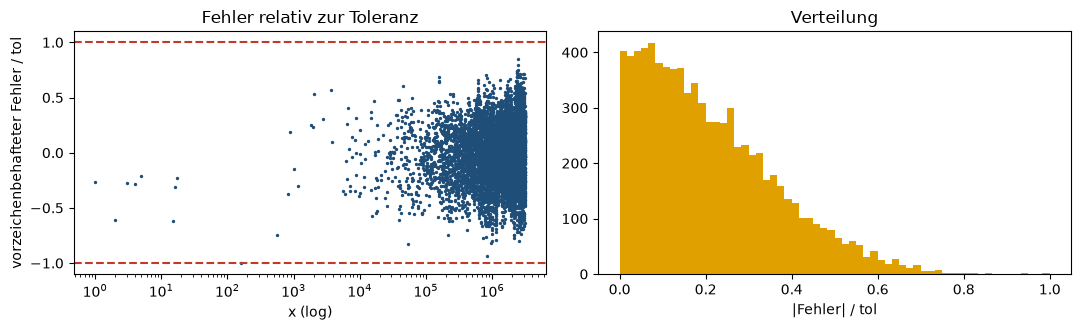

In [11]:
edge = [1, 2, 3, 4, 5, 15, 16, 17, 161, 4**5, 4**10, SPEC.max_x - 1, SPEC.max_x]
xs = np.unique(np.concatenate([rng.integers(1, SPEC.max_x + 1, 8192), edge]).astype(np.uint64))
scratch = km.array([km.q(i) for i in range(22, sota.num_qubits)])

sim = km.Simulator(batch_size=len(xs), debug_print=False, seed=2026)
sim.write_across_shots(XREG, to_bits(xs))
t = time.time(); sim.do(sota); dt = time.time() - t

x_back = V.from_bits(sim.read_across_shots(XREG))
dirty = sim.read_across_shots(scratch).any(axis=0)
theta = np.array([V.half_turns_to_units(Fraction(sim.read_shot_phase(i))) for i in range(len(xs))], dtype=np.uint64)
target, tol = V.reference_values(SPEC, xs)
err = (theta - target).view(np.int64)
ratio_e = np.abs(err).astype(float) / tol.astype(float)

print(f'{len(xs):,} Shots in {dt*1000:.0f} ms')
print('x wiederhergestellt:      ', bool(np.array_equal(x_back, xs)))
print('Scratch überall |0⟩:      ', not dirty.any())
print(f'max |Fehler|/tol:          {ratio_e.max():.4f}  bei x={int(xs[ratio_e.argmax()])}')
print('alle innerhalb Toleranz:  ', bool((ratio_e <= 1).all()))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.scatter(xs, err.astype(float) / tol.astype(float), s=2, c='#1f4e79')
a1.axhline(1, c='#c0392b', ls='--'); a1.axhline(-1, c='#c0392b', ls='--'); a1.set_xscale('log')
a1.set_xlabel('x (log)'); a1.set_ylabel('vorzeichenbehafteter Fehler / tol'); a1.set_title('Fehler relativ zur Toleranz')
a2.hist(ratio_e, bins=60, color='#e0a100'); a2.set_xlabel('|Fehler| / tol'); a2.set_title('Verteilung')
plt.tight_layout(); plt.show()

**Messzufall:** Dasselbe `x` wird im Wettbewerb 64-mal simuliert, jedes Mal mit anderen HMR-Ausgängen. Prüfen wir am Worst-Case `x = 161`, dass die Phase trotzdem stimmt:

In [12]:
n_shots = 256
sim = km.Simulator(batch_size=n_shots, debug_print=False, seed=99)
sim.write_across_shots(XREG, to_bits(np.full(n_shots, 161)))
sim.do(sota)
bits = sim.read_across_shots(km.array([km.b(i) for i in range(sota.num_bits)]))   # (num_bits, shots)
patterns = len({bits[:, s].tobytes() for s in range(n_shots)})
th = np.array([V.half_turns_to_units(Fraction(sim.read_shot_phase(i))) for i in range(n_shots)], dtype=np.uint64)
tg, tl = V.reference_values(SPEC, np.array([161], dtype=np.uint64))
e = np.abs((th - tg[0]).view(np.int64)).astype(float) / float(tl[0])
print(f'{patterns} verschiedene Messmuster in {n_shots} Shots')
print(f'|Fehler|/tol über alle Shots: min {e.min():.6f}  max {e.max():.6f}')

256 verschiedene Messmuster in 256 Shots
|Fehler|/tol über alle Shots: min 0.999324  max 0.999324


Jeder Shot hat ein anderes Messmuster, und trotzdem ist die Phase in allen Shots **bit-genau identisch**. Das ist **messbasierte Uncomputation in Aktion**: Der Zufall wird durch die bedingten CZ- und T-Korrekturen exakt kompensiert. Die Toffoli-Zahl hängt dagegen vom Zufall ab, deshalb mittelt der Verifier sie.

## 7 · Woher kommen die ~21×?

In [13]:
r_, s_ = RES['Referenz'], RES['SOTA']
rows = [
    ('Qubits Q', r_['num_qubits'], s_['num_qubits']),
    ('Toffoli-Äquivalent C', r_['toffoli_equivalent'], s_['toffoli_equivalent']),
    ('  mittlere Toffolis', r_['toffoli_count'], s_['toffoli_count']),
    ('  Rotationsanteil (Tof-eq)', zerlegung(r_)[0]['Rotationen / 4'], zerlegung(s_)[0]['Rotationen / 4']),
    ('Score Q·C', r_['score'], s_['score']),
]
print(f"{'':30s}{'Referenz':>14s}{'SOTA':>12s}{'Faktor':>9s}")
for k, a_, b_ in rows: print(f'{k:30s}{a_:>14,.1f}{b_:>12,.1f}{a_/b_:>8.2f}×')
print(f"\nFehlerbudget genutzt: Referenz {r_['worst_error_over_tolerance']:.3f} → SOTA {s_['worst_error_over_tolerance']:.3f}")
print(f"HMR je statischem Toffoli: Referenz {6727/7735:.2f} → SOTA {856/1487:.2f}")

                                    Referenz        SOTA   Faktor
Qubits Q                               260.0        62.0    4.19×
Toffoli-Äquivalent C                 7,987.6     1,589.3    5.03×
  mittlere Toffolis                  7,735.0     1,289.3    6.00×
  Rotationsanteil (Tof-eq)             252.3       294.8    0.86×
Score Q·C                        2,076,774.2    98,533.9   21.08×

Fehlerbudget genutzt: Referenz 0.477 → SOTA 0.999
HMR je statischem Toffoli: Referenz 0.87 → SOTA 0.58


**Die 21× sind ≈ 4,2× (Breite) mal ≈ 5,0× (Gatter).** Hinter jedem Faktor stecken Mechanismen, die wir in diesem Notebook **gesehen** haben:

| Mechanismus | Wirkt auf | Beleg hier |
|---|---|---|
| Bit-serielles Phase-Streaming (1 Qubit statt ganzem `y₁`) | Q | Abschnitt 5a |
| Aggressives Pebbling (40 Scratch-Qubits, viele Neustarts) | Q | Abschnitt 5b |
| Messbasierte Uncomputation (HMR + bedingte Korrektur) | Toffolis | 856 HMR, Abschnitt 6 |
| Bedingte Blöcke (nur ausführen, wenn Messbit = 1) | **mittlere** Toffolis | statisch 1.487 → Mittel ~1.289 |
| Fehlerbudget fast voll ausgeschöpft (0,999 statt 0,48) | Toffolis (schmalere Arithmetik) | Abschnitt 2 |
| Zwei-Raten-Phase (grob nach Seed, fein nach Korrektur) | beides | Abschnitt 4 |
| LP-nachoptimierte Rotationsgewichte | Fehlerbudget | Abschnitt 4 (Winkel-Tabelle) |

**Nicht gemessen (offen):** Wie die Normalisierung und der Seed im SOTA genau aufgebaut sind (Tabelle? Polynom? Bitbreiten?) und wie viele Toffolis jede Stufe kostet. Ohne Tags bräuchte man dafür eine eigene Datenfluss-Analyse.

## 8 · Wo liegen unsere Hebel?

Erst die Rechnung, die man immer machen sollte: **Was bringt eine Verbesserung bei invsqrt dem Gesamtscore?** Der Score ist das geometrische Mittel, also bringt Faktor `f` bei invsqrt insgesamt `f^(1/3)`.

In [14]:
C0, Q0 = s_['toffoli_equivalent'], s_['num_qubits']
per_rot_tofeq = V.rotation_t_count(s_['rotation_eps']) / 4
def gm_gain(newQ, newC): return ((Q0 * C0) / (newQ * newC)) ** (1/3) - 1
szen = [
    ('1 Rotation weniger',            Q0, C0 - per_rot_tofeq),
    ('n_rot 41→33, OHNE Routing-Kosten', Q0, C0 - 8 * per_rot_tofeq),
    ('Rest-margin verdoppeln',        Q0, C0 - 41 * 0.56 / 4),
    ('alle Rotationen gratis (Utopie)', Q0, C0 - zerlegung(s_)[0]['Rotationen / 4']),
    ('100 mittlere Toffolis weniger', Q0, C0 - 100),
    ('1 Qubit weniger (61)',          Q0 - 1, C0),
]
print(f"{'Szenario':34s}{'ΔC (Tof-eq)':>12s}{'invsqrt-Faktor':>16s}{'ΔGesamt-GM':>12s}")
for name, q, c in szen:
    print(f'{name:34s}{c-C0:>12.1f}{RES["Referenz"]["score"]/(q*c):>15.3f}×{gm_gain(q, c):>+11.2%}')

Szenario                           ΔC (Tof-eq)  invsqrt-Faktor  ΔGesamt-GM
1 Rotation weniger                        -7.2         21.173×     +0.15%
n_rot 41→33, OHNE Routing-Kosten         -57.5         21.868×     +1.24%
Rest-margin verdoppeln                    -5.7         21.153×     +0.12%
alle Rotationen gratis (Utopie)         -294.8         25.878×     +7.08%
100 mittlere Toffolis weniger           -100.0         22.492×     +2.19%
1 Qubit weniger (61)                       0.0         21.422×     +0.54%


**Was wir schon gemessen haben** (aus den Berichten der Subagenten B und D vom 03.11., `work/p0_reports/report_B_invsqrt_c.md` und `work/pa_prexperiment/report_D_pa_prexperiment.md`; in diesem Notebook **nicht** nachgerechnet):

| Idee | Ergebnis | Status |
|---|---|---|
| Rest-margin `c` vergrößern | `c` sitzt an der LP-Decke (Re-Solve 58.597.852,7 vs. shipped 58.597.850) | **tot** (< +0,05 % GM) |
| **P-A**: Rotationen durch dyadisches Bit-Streaming ersetzen | n_rot sinkt nur 41 → 33 (nicht → 0). Die Ersparnis (Zeile oben in der Tabelle) wird vom nötigen `s`-Routing mit 221 Toffolis mehr als aufgefressen | **NO-GO** (ΔGM −2,06 %) |
| **P-B**: Constant-Seed-Neubau | bestenfalls 0,614× vs. SOTA (384 Q, 8.581 Toffolis) | **NO-GO** |
| Product-Caching / HMR-Port von busyaprime | 0 echte Produkt-Wiederholungen im Schaltkreis | **tot** |
| Breite 62 → 61 | siehe Tabelle: +0,5 % GM pro Qubit | **offen**, nicht untersucht |
| Mittlere Toffolis am Newton-Kern | Kern ≈ 700 von 1.289 Toffolis; die bekannten Rewrites sind schon eingebaut | **nahe der Decke** |

**Fazit:** Auf der aktuellen Single-Newton-Architektur ist invsqrt **weitgehend gesättigt**. Ein echter Sprung bräuchte eine **neue Architektur**, die gleichzeitig Breite *und* Toffolis senkt. Der einzige kleine offene Posten ist ein Qubit weniger, also +0,5 % GM pro eingespartem Qubit, falls das ohne Toffoli-Aufschlag geht.

## Übungen

1. **Abschnitt 2:** Lass `verify()` mit `shots_per_x=4` laufen (~20 s). Wie stark schwanken `toffoli_count` und `worst_error_over_tolerance` gegenüber `shots_per_x=1`?
2. **Abschnitt 4:** Ersetze im Text des SOTA-Schaltkreises **einen** feinen Winkel durch die exakte Zweierpotenz 2⁻ᵏ und verifiziere neu. Fällt er durch? Wie viel `margin` geht verloren?
3. **Abschnitt 4:** Lösche die feinste Rotation ganz (eine Zeile). Wie verändert sich der Score? (Tipp: n_rot sinkt, aber margin auch.)
4. **Abschnitt 5:** Finde mit `per_qubit()` das Qubit mit den meisten Neustarts und drucke 30 Instruktionen um seine ersten drei Nutzungen. Welche Rolle spielt es?
5. **Abschnitt 3:** Öffne den Flame-Chart der Referenz und finde die Stufe mit der größten **Breite**. Stimmt sie mit der Stufe mit den meisten Toffolis überein?